# 86 · Contrastive image-text learning from scratch on TableTop: the CLIP (InfoNCE) and SigLIP losses

In [1]:
import time, numpy as np, torch, torch.nn as nn, torch.nn.functional as F, matplotlib.pyplot as plt
from vlacourse import TableTop, show_images

device = "cuda" if torch.cuda.is_available() else "cpu"
RELS = ["left of", "right of", "in front of", "behind"]

def relation(p, q):
    """Relation of p to q as seen from the 'top' camera (x toward the viewer's front, y to the left)."""
    d = p - q
    if abs(d[1]) > abs(d[0]):
        return "left of" if d[1] > 0 else "right of"
    return "in front of" if d[0] > 0 else "behind"

def make_dataset(n, seed=0):
    env = TableTop(cameras=("top",), image_size=(64, 64), seed=seed)
    objs = [("cube", c) for c in env.cube_colors] + [("tray", c) for c in env.tray_colors]
    rng = np.random.default_rng(seed); imgs, caps = [], []
    for i in range(n):
        env.reset(seed=seed * 10 ** 6 + i)
        (k1, c1), (k2, c2) = [objs[j] for j in rng.choice(len(objs), 2, replace=False)]
        p = env.body_pos(f"{k1}_{c1}")[:2]; q = env.body_pos(f"{k2}_{c2}")[:2]
        imgs.append(env.render("top")); caps.append(f"the {c1} {k1} is {relation(p, q)} the {c2} {k2}")
    return np.array(imgs), caps

class Vocab:
    def __init__(self, caps):
        self.w = {w: i + 1 for i, w in enumerate(sorted({w for c in caps for w in c.split()}))}
    def __call__(self, caps):
        L = max(len(c.split()) for c in caps)
        return torch.tensor([[self.w.get(w, 0) for w in c.split()] + [0] * (L - len(c.split())) for c in caps])

class ImageEnc(nn.Module):
    def __init__(self, d=128):
        super().__init__()
        self.net = nn.Sequential(nn.Conv2d(3, 32, 3, 2, 1), nn.ReLU(), nn.Conv2d(32, 64, 3, 2, 1), nn.ReLU(), nn.Conv2d(64, 128, 3, 2, 1), nn.ReLU(),
                                 nn.Conv2d(128, 128, 3, 2, 1), nn.ReLU(), nn.Flatten(), nn.Linear(128 * 16, d))
    def forward(self, x):
        return self.net(x)

class TextEnc(nn.Module):
    def __init__(self, vocab, d=128):
        super().__init__()
        self.emb = nn.Embedding(vocab + 1, 64, padding_idx=0); self.gru = nn.GRU(64, d, batch_first=True)
    def forward(self, t):
        return self.gru(self.emb(t))[1][0]

def clip_loss(zi, zt, logit_scale):
    logits = logit_scale.exp() * zi @ zt.T
    target = torch.arange(len(zi), device=zi.device)
    return (F.cross_entropy(logits, target) + F.cross_entropy(logits.T, target)) / 2

def siglip_loss(zi, zt, t, b):
    logits = zi @ zt.T * t.exp() + b
    labels = 2 * torch.eye(len(zi), device=zi.device) - 1
    return -F.logsigmoid(labels * logits).sum() / len(zi)

def train(kind, imgs, toks, steps=3000, B=256):
    torch.manual_seed(0)
    fi, ft = ImageEnc().to(device), TextEnc(len(vocab.w)).to(device)
    t = nn.Parameter(torch.tensor(np.log(10.0), device=device)); b = nn.Parameter(torch.tensor(-10.0, device=device))
    opt = torch.optim.Adam(list(fi.parameters()) + list(ft.parameters()) + [t, b], 1e-3)
    X = torch.tensor(imgs).permute(0, 3, 1, 2).float().div(255).to(device); T = toks.to(device)
    for step in range(steps):
        idx = torch.randint(0, len(X), (B,), device=device)
        zi, zt = F.normalize(fi(X[idx]), dim=-1), F.normalize(ft(T[idx]), dim=-1)
        loss = clip_loss(zi, zt, t) if kind == "clip" else siglip_loss(zi, zt, t, b)
        opt.zero_grad(); loss.backward(); opt.step()
    return fi.eval(), ft.eval()

rendered 6500 images in 5s; vocabulary 14 words


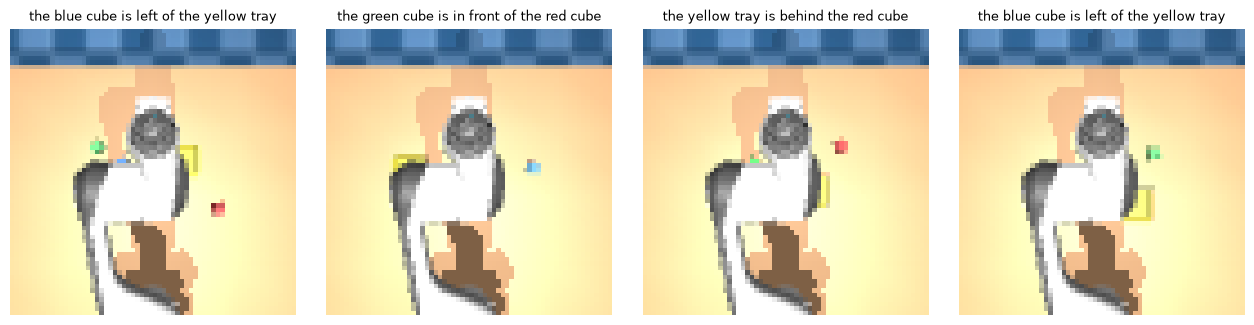

In [2]:
t0 = time.time()
imgs, caps = make_dataset(6000, seed=0)
test_imgs, test_caps = make_dataset(500, seed=1)
vocab = Vocab(caps)
print(f"rendered {len(imgs) + len(test_imgs)} images in {time.time() - t0:.0f}s; vocabulary {len(vocab.w)} words")
show_images(list(imgs[:4]), caps[:4], cols=4, size=3.2)

In [3]:
models = {k: train(k, imgs, vocab(caps)) for k in ["clip", "siglip"]}

@torch.no_grad()
def evaluate_relations(fi, ft):
    X = torch.tensor(test_imgs).permute(0, 3, 1, 2).float().div(255).to(device)
    zi = F.normalize(fi(X), dim=-1)
    correct = 0
    for i, cap in enumerate(test_caps):
        words = cap.split(" is ")[0], cap.split(" is ")[1]
        rest = words[1]
        rel = next(r for r in RELS if rest.startswith(r)); tail = rest[len(rel):]
        cands = [f"{words[0]} is {r}{tail}" for r in RELS]
        zt = F.normalize(ft(vocab(cands).to(device)), dim=-1)
        correct += int((zi[i] @ zt.T).argmax().item() == RELS.index(rel))
    return correct / len(test_caps)

for k, (fi, ft) in models.items():
    print(f"{k:6s}: zero-shot relation classification on held-out scenes = {evaluate_relations(fi, ft):.2f} (chance 0.25)")

clip  : zero-shot relation classification on held-out scenes = 0.52 (chance 0.25)
siglip: zero-shot relation classification on held-out scenes = 0.39 (chance 0.25)


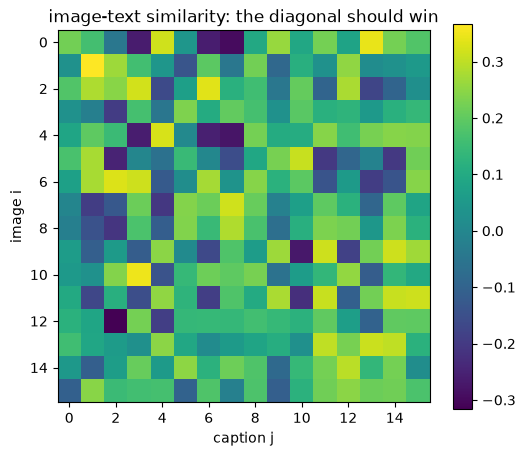

In [4]:
fi, ft = models["clip"]
with torch.no_grad():
    X = torch.tensor(test_imgs[:16]).permute(0, 3, 1, 2).float().div(255).to(device)
    S = F.normalize(fi(X), dim=-1) @ F.normalize(ft(vocab(test_caps[:16]).to(device)), dim=-1).T
plt.figure(figsize=(6, 5)); plt.imshow(S.cpu(), cmap="viridis"); plt.xlabel("caption j"); plt.ylabel("image i"); plt.colorbar()
plt.title("image-text similarity: the diagonal should win"); plt.show()